## Setup

In [1]:
import os
import numpy as np

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
from torchvision.io import decode_image

In [2]:
from google.colab import drive
drive.mount('/content/drive')

base_dir = "/content/drive/MyDrive/Lucas"

Mounted at /content/drive


## Copiando os embeddings para o ambiente de execução

In [3]:
save_path = base_dir + "/Embeddings"
local_path = "/content/Embeddings"

In [4]:
import shutil

shutil.copytree(save_path, local_path, dirs_exist_ok=True)

'/content/Embeddings'

## Dataset (BMT embeddings)

In [5]:
class BMT_embeddings(Dataset):
    def __init__(self, label, img_dir=local_path):
        '''
        label:
          0 <-> 'NIL'
          1 <-> 'LSIL'
          2 <-> 'HSIL'
        '''
        self.label_dict = {'NIL':0, 'LSIL':1, 'HSIL':2}
        self.label = label
        self.img_dir = img_dir + "/" + self.label

    def __len__(self):
        return 200

    def __getitem__(self, idx):
        embed_path = self.img_dir + "/" + f'{idx+1}.pt'
        embed = torch.load(embed_path, map_location="cpu")
        return embed, self.label_dict[self.label]

In [6]:
nil_embed_data = BMT_embeddings(label='NIL')
lsil_embed_data = BMT_embeddings(label='LSIL')
hsil_embed_data = BMT_embeddings(label='HSIL')

## Train-Test split

In [7]:
# 60% (treino) : 40% (teste + validação)
from torch.utils.data import random_split

split_generator = torch.Generator().manual_seed(31)

# NIL
training_nil_data, validation_nil_data = random_split(
    nil_embed_data, [120, 80], generator=split_generator
)
validation_nil_data, testing_nil_data = random_split(
    validation_nil_data, [40, 40], generator=split_generator
)

# LSIL
training_lsil_data, validation_lsil_data = random_split(
    lsil_embed_data, [120, 80], generator=split_generator
)
validation_lsil_data, testing_lsil_data = random_split(
    validation_lsil_data, [40, 40], generator=split_generator
)

# HSIL
training_hsil_data, validation_hsil_data = random_split(
    hsil_embed_data, [120, 80], generator=split_generator
)
validation_hsil_data, testing_hsil_data = random_split(
    validation_hsil_data, [40, 40], generator=split_generator
)

In [8]:
# Concatenação das classes
training_data = training_nil_data + training_lsil_data + training_hsil_data
validation_data = validation_nil_data + validation_lsil_data + validation_hsil_data
testing_data = testing_nil_data + testing_lsil_data + testing_hsil_data

## Dataloader (BMT embeddings)

In [9]:
training_dataloader = DataLoader(training_data, batch_size=1, shuffle=True)
validation_dataloader = DataLoader(validation_data, batch_size=1)
testing_dataloader = DataLoader(testing_data, batch_size=1)

## Arquitetura ABMIL topk

In [10]:
'''
Feito com auxílio do  Claude Code (Opus 5.5 / High)
'''

import torch.nn as nn

class GatedAttentionMIL(nn.Module):
    """ABMIL com atenção com porta (Ilse et al., 2018)."""

    def __init__(self, topk=8, in_dim=1024, hid=256, att_hid=128, n_classes=3, p_drop=0.25):
        super().__init__()
        self.topk = topk
        # projeção: reduz 1024 → 256 antes da atenção
        self.proj = nn.Sequential(
            nn.Linear(in_dim, hid),
            nn.ReLU(),
            nn.Dropout(p_drop),
        )
        # dois ramos da atenção com porta
        self.att_V = nn.Sequential(nn.Linear(hid, att_hid), nn.Tanh())
        self.att_U = nn.Sequential(nn.Linear(hid, att_hid), nn.Sigmoid())
        self.att_w = nn.Linear(att_hid, 1)

        self.classifier = nn.Linear(hid, n_classes)

    def topk_idx(self, tensor, k):
        '''
        tensor.shape == [1,N,3]
        Função topk recebe os logits da classificação e retorna os índices dos topk
        tiles suspeitos com base no score (P(lsil) + P(hsil)) / P(nil)
        '''
        tensor = tensor.squeeze(0)  # [N,3]
        scores = []
        for logits in tensor:
          nil_score =  logits[0].item()
          lsil_score = logits[1].item()
          hsil_score = logits[2].item()

          p = torch.softmax(torch.tensor([nil_score,lsil_score,hsil_score]),dim=0)

          score = (p[1].item() + p[2].item()) / max(p[0].item(), 1e-12)         # Evita divisão por zero
          scores.append(score)

        scores = torch.tensor(scores)
        _, idx = torch.topk(scores,k)
        idx = idx.flatten()
        return idx

    def forward(self, bags):                    # bags: [B, N, 1024]
        h = self.proj(bags)                     # [B, N, 256]

        if self.topk == -1:
          topk = h.shape[1]
        else:
          topk = min(self.topk, h.shape[1])

        idx = self.topk_idx(self.classifier(h),topk)

        h = h[:,idx]

        a = self.att_w(self.att_V(h) * self.att_U(h))   # [B, topk, 1]
        a = torch.softmax(a, dim=1)                     # pesos somam 1 no bag

        z = (a * h).sum(dim=1)              # [B, 256] — bag embedding

        return self.classifier(z)

## Treino ABMIL para escolher topk

In [ ]:
for topk in [1,2,4,8,16,32,-1]:
  best_losses = []
  print(f"topk={topk}")
  for i in range(10):
    abmil = GatedAttentionMIL(topk=topk)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    abmil.to(device)
    abmil.train()
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(abmil.parameters(), lr=1e-3)
    best_val_loss = float('inf')
    for epoch in range(50):
        abmil.train()
        for batch, (X, y) in enumerate(training_dataloader):
            X, y = X.to(device), y.to(device)

            # Compute prediction error
            pred = abmil(X)
            loss = loss_fn(pred, y)

            # Backpropagation
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        abmil.eval()
        total_loss = 0
        with torch.no_grad():
            for batch, (X, y) in enumerate(validation_dataloader):
                X, y = X.to(device), y.to(device)

                # Compute prediction error
                pred = abmil(X)
                loss = loss_fn(pred, y)

                total_loss += loss.item()
        total_loss = total_loss / len(validation_dataloader)

        if i == 9:
          if epoch % 10 == 0:
            print(f"Fim da época {epoch+1}/50: val_loss = {total_loss}")

        if total_loss < best_val_loss:
            best_val_loss = total_loss

    best_losses.append(best_val_loss)
  best_loss_mean = np.array(best_losses).mean()
  print(f"Best loss (mean): {best_loss_mean}")
  print()


topk=1
Fim da época 1/50: val_loss = 0.46572051460000996
Fim da época 11/50: val_loss = 0.4114161970532958
Fim da época 21/50: val_loss = 0.676269345899023
Fim da época 31/50: val_loss = 0.8172135780064422
Fim da época 41/50: val_loss = 0.8352163065544443
Best loss (mean): 0.3107656967773055

topk=2
Fim da época 1/50: val_loss = 0.5413777008575077
Fim da época 11/50: val_loss = 1.2269879536644974
Fim da época 21/50: val_loss = 0.5320218540110527
Fim da época 31/50: val_loss = 0.8098987859605901
Fim da época 41/50: val_loss = 2.044630353570108
Best loss (mean): 0.22574366180981026

topk=4
Fim da época 1/50: val_loss = 0.5031428194592081
Fim da época 11/50: val_loss = 0.3541355223366028
Fim da época 21/50: val_loss = 0.2530097524600237
Fim da época 31/50: val_loss = 0.4588581741221532
Fim da época 41/50: val_loss = 2.973529735803391
Best loss (mean): 0.1846125826162852

topk=8
Fim da época 1/50: val_loss = 0.5032452007327568
Fim da época 11/50: val_loss = 0.28175023426352447
Fim da época

## Treino ABMIL topk=8

In [16]:
abmil = GatedAttentionMIL(topk=8)
abmil

GatedAttentionMIL(
  (proj): Sequential(
    (0): Linear(in_features=1024, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
  )
  (att_V): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Tanh()
  )
  (att_U): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Sigmoid()
  )
  (att_w): Linear(in_features=128, out_features=1, bias=True)
  (classifier): Linear(in_features=256, out_features=3, bias=True)
)

In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"

abmil.to(device)
abmil.train()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(abmil.parameters(), lr=1e-3)
best_val_loss = float('inf')

In [18]:
for epoch in range(50):
    abmil.train()
    for batch, (X, y) in enumerate(training_dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = abmil(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    abmil.eval()
    total_loss = 0
    with torch.no_grad():
        for batch, (X, y) in enumerate(validation_dataloader):
            X, y = X.to(device), y.to(device)

            # Compute prediction error
            pred = abmil(X)
            loss = loss_fn(pred, y)

            total_loss += loss.item()
    total_loss = total_loss / len(validation_dataloader)

    print(f"Fim da época {epoch+1}/50: val_loss = {total_loss}")

    if total_loss < best_val_loss:
        best_val_loss = total_loss
        torch.save(abmil.state_dict(), base_dir + "/" + "abmil_topk.pth")

print(f"Best loss: {best_val_loss}")

Fim da época 1/50: val_loss = 0.2804287014058597
Fim da época 2/50: val_loss = 0.2844623229896115
Fim da época 3/50: val_loss = 0.5582235743900306
Fim da época 4/50: val_loss = 0.30135029470282987
Fim da época 5/50: val_loss = 0.1891411046508115
Fim da época 6/50: val_loss = 0.15516753337392988
Fim da época 7/50: val_loss = 0.2056846721750438
Fim da época 8/50: val_loss = 0.4282724318488533
Fim da época 9/50: val_loss = 0.2372320226560793
Fim da época 10/50: val_loss = 0.1880538432737911
Fim da época 11/50: val_loss = 0.22037146677711708
Fim da época 12/50: val_loss = 0.18726921902332255
Fim da época 13/50: val_loss = 0.18202395667811308
Fim da época 14/50: val_loss = 0.23089506634384768
Fim da época 15/50: val_loss = 0.2633254531169599
Fim da época 16/50: val_loss = 0.16809546557868102
Fim da época 17/50: val_loss = 0.2286698241644697
Fim da época 18/50: val_loss = 0.2729257368083982
Fim da época 19/50: val_loss = 0.790831529605227
Fim da época 20/50: val_loss = 0.3545223119986115
Fim

## Avaliação ABMIL topk=8

In [19]:
device = "cuda" if torch.cuda.is_available() else "cpu"
abmil = GatedAttentionMIL(topk=8).to(device)
state = torch.load(base_dir + "/abmil_topk.pth", map_location='cpu')
abmil.load_state_dict(state)

for param in abmil.parameters():
    param.requires_grad = False

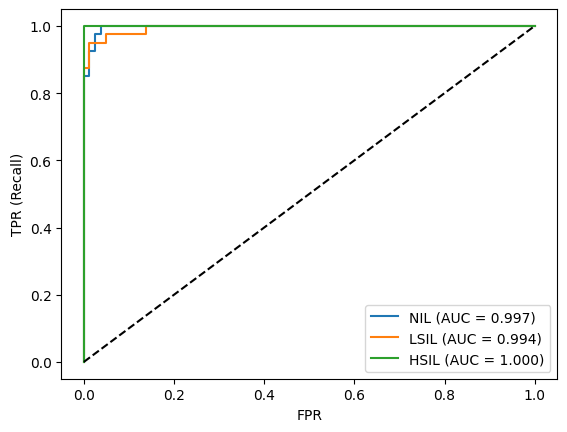

In [20]:
# Curva AUC
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

abmil.eval()
all_probs, all_labels = [], []

with torch.no_grad():
    for X, y in testing_dataloader:
        X = X.to(device)
        probs = torch.softmax(abmil(X), dim=1)
        all_probs.append(probs.cpu())
        all_labels.append(y)

probs = torch.cat(all_probs).numpy()      # (N, 3)
labels = torch.cat(all_labels).numpy()    # (N,)

classes = ['NIL', 'LSIL', 'HSIL']

for i, nome in enumerate(classes):
    fpr, tpr, _ = roc_curve((labels == i).astype(int), probs[:, i])
    plt.plot(fpr, tpr, label=f'{nome} (AUC = {auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--')           # classificador aleatório
plt.xlabel('FPR')
plt.ylabel('TPR (Recall)')
plt.legend()
plt.show()